# Week 4 Day 2 — Core Supervised Learning
**Dataset:** Adult Census Income

**Goal:** train two models (Logistic Regression and Decision Tree) and compare them with the Day 1 baseline.

## Step 0: Load the data (same split as Day 1)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

In [2]:
# Upload adult.csv from my computer
from google.colab import files
uploaded = files.upload()

Saving adult.csv to adult.csv


In [3]:
df = pd.read_csv("adult.csv")

# "?" means missing value, so change it to NaN
df = df.replace("?", np.nan)

# Target: 1 for >50K, 0 for <=50K
df["target"] = df["income"].map({"<=50K": 0, ">50K": 1})

df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,target
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K,0
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K,0
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K,0
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K,0
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K,0


In [4]:
# Same split as Day 1
X = df.drop(columns=["income", "target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train rows:", len(X_train))
print("Test rows :", len(X_test))

Train rows: 26048
Test rows : 6513


## Task 1: Preprocessing

First I list my features. I do not use two columns:
- `fnlwgt`: it is not about the person.
- `education`: it is the same as `education.num`.

In [5]:
numeric_features = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]

categorical_features = ["workclass", "marital.status", "occupation",
                        "relationship", "race", "sex", "native.country"]

print("Numeric features    :", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features    : 5
Categorical features: 7


In [6]:
# ---------- For number columns ----------
# 1) Fill missing values with the MEDIAN (middle value).
#    Why: capital.gain has a few very big values. They change the mean a lot,
#    but they do not change the median.
#    Not used: mean (bad with very big values), deleting rows (loses data).
# 2) StandardScaler: puts all numbers on the same scale.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# ---------- For text columns ----------
# 1) Fill missing values with the word "Missing".
#    Why: "no answer" can also be useful information.
#    Not used: most_frequent (it hides that the value was missing).
# 2) OneHotEncoder: makes one 0/1 column for each category.
#    Why: jobs or countries have no order, so 1, 2, 3 would be wrong.
#    Not used: OrdinalEncoder / LabelEncoder (they make a fake order).
#    handle_unknown="ignore": no error if the test data has a new category.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# ---------- Join both ----------
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

## Task 2: Train two models

A pipeline = preprocessing + model together. It learns only from the training data, so there is no data leakage.

In [7]:
# Model 1: Logistic Regression
# solver="lbfgs" supports regularization (L2). C sets how strong it is.
log_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(solver="lbfgs", C=1.0, max_iter=1000, random_state=42)),
])

# Model 2: Decision Tree
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42)),
])

In [8]:
# Train on the TRAINING set only
log_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("Both models are trained.")

Both models are trained.


## Task 3: Test on the hold-out test set

In [9]:
# Predictions (0 or 1)
log_pred = log_model.predict(X_test)
tree_pred = tree_model.predict(X_test)

# Probabilities of class 1 (needed for ROC AUC and PR AUC)
log_proba = log_model.predict_proba(X_test)[:, 1]
tree_proba = tree_model.predict_proba(X_test)[:, 1]

# Day 1 baseline: education.num >= 13
base_pred = (X_test["education.num"] >= 13).astype(int)

In [10]:
results = pd.DataFrame({
    "Day 1 baseline": [
        accuracy_score(y_test, base_pred),
        precision_score(y_test, base_pred),
        recall_score(y_test, base_pred),
        f1_score(y_test, base_pred),
        roc_auc_score(y_test, base_pred),
        average_precision_score(y_test, base_pred),
    ],
    "Logistic Regression": [
        accuracy_score(y_test, log_pred),
        precision_score(y_test, log_pred),
        recall_score(y_test, log_pred),
        f1_score(y_test, log_pred),
        roc_auc_score(y_test, log_proba),
        average_precision_score(y_test, log_proba),
    ],
    "Decision Tree": [
        accuracy_score(y_test, tree_pred),
        precision_score(y_test, tree_pred),
        recall_score(y_test, tree_pred),
        f1_score(y_test, tree_pred),
        roc_auc_score(y_test, tree_proba),
        average_precision_score(y_test, tree_proba),
    ],
}, index=["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"])

results.round(3)

,Day 1 baseline,Logistic Regression,Decision Tree
accuracy,0.758,0.853,0.817
precision,0.498,0.735,0.628
recall,0.511,0.610,0.592
f1,0.505,0.667,0.610
roc_auc,0.674,0.904,0.758
pr_auc,0.372,0.767,0.493


**Result:** both models are better than the Day 1 baseline (F1 0.51). Logistic Regression is the best.

### ROC curves

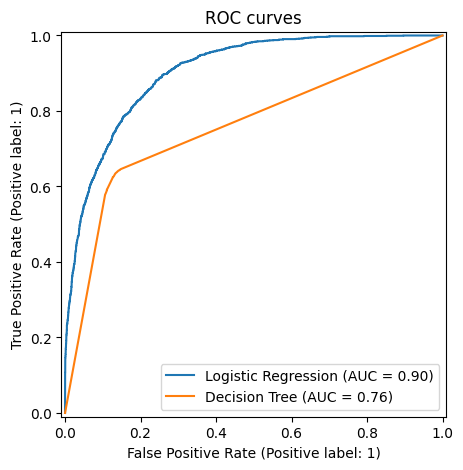

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, log_proba, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, tree_proba, name="Decision Tree", ax=ax)
plt.title("ROC curves")
plt.show()

### Precision-Recall curves

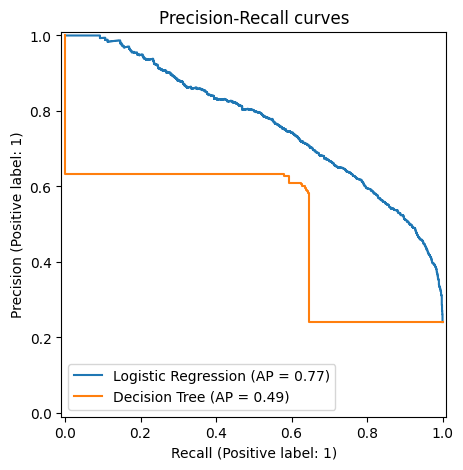

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, log_proba, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, tree_proba, name="Decision Tree", ax=ax)
plt.title("Precision-Recall curves")
plt.show()

### Confusion matrices

[[4600  345]
 [ 611  957]]


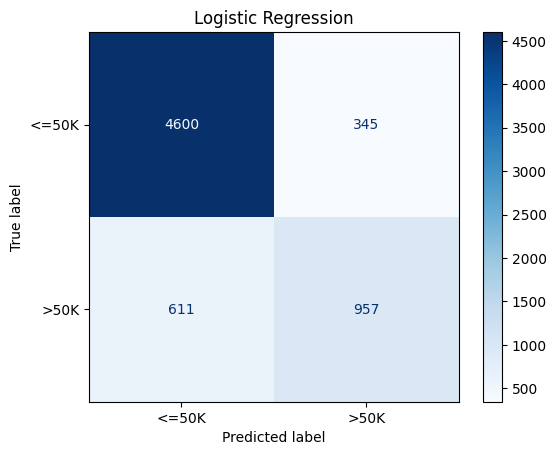

In [13]:
print(confusion_matrix(y_test, log_pred))

ConfusionMatrixDisplay.from_predictions(y_test, log_pred, display_labels=["<=50K", ">50K"], cmap="Blues")
plt.title("Logistic Regression")
plt.show()

[[4394  551]
 [ 639  929]]


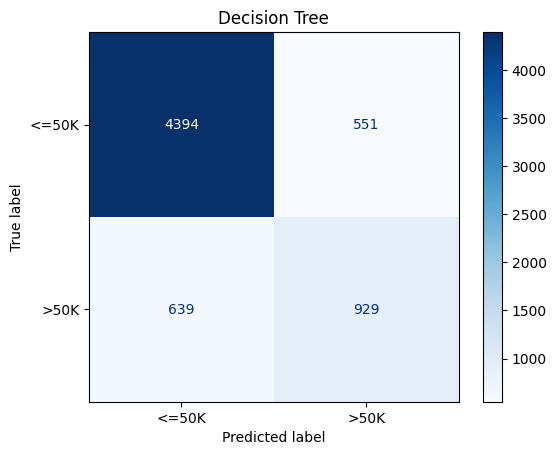

In [14]:
print(confusion_matrix(y_test, tree_pred))

ConfusionMatrixDisplay.from_predictions(y_test, tree_pred, display_labels=["<=50K", ">50K"], cmap="Blues")
plt.title("Decision Tree")
plt.show()

**Which error is more common?**
- **False negatives** (missed high earners) are more common in both models.
- Logistic Regression: 611 missed vs 345 wrongly picked.
- Decision Tree: 639 missed vs 551 wrongly picked.
- So recall is lower than precision, and this keeps the F1 score down. Next I should try to find more high earners.

## Task 4: Interpretability

### Logistic Regression: which features matter?
- Positive number = pushes towards >50K.
- Negative number = pushes towards <=50K.

In [15]:
# Get the feature names and the coefficients out of the pipeline
feature_names = log_model.named_steps["preprocess"].get_feature_names_out()
coefficients = log_model.named_steps["model"].coef_[0]

coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
coef_table = coef_table.sort_values("coefficient", ascending=False)

In [16]:
# Top 10 positive
coef_table.head(10).round(2)

,feature,coefficient
2,num__capital.gain,2.30
15,cat__marital.status_Married-AF-spouse,1.43
49,cat__native.country_Cambodia,1.31
16,cat__marital.status_Married-civ-spouse,1.29
41,cat__relationship_Wife,1.06
24,cat__occupation_Exec-managerial,0.86
69,cat__native.country_Italy,0.85
34,cat__occupation_Tech-support,0.77
1,num__education.num,0.72
32,cat__occupation_Protective-serv,0.69


In [17]:
# Top 10 negative
coef_table.tail(10).round(2)

,feature,coefficient
13,cat__workclass_Without-pay,-0.87
52,cat__native.country_Columbia,-0.92
47,cat__sex_Female,-0.94
54,cat__native.country_Dominican-Republic,-0.97
25,cat__occupation_Farming-fishing,-0.99
88,cat__native.country_Vietnam,-1.01
60,cat__native.country_Greece,-1.07
18,cat__marital.status_Never-married,-1.12
39,cat__relationship_Own-child,-1.21
30,cat__occupation_Priv-house-serv,-1.47


**Top positive (more likely >50K):**
- `capital.gain`: more investment profit.
- `Married-civ-spouse`: married people.
- `Wife`: also married people.
- `education.num`: more education.
- `Exec-managerial`: manager jobs.
- `Tech-support`: technical jobs.
- `Protective-serv`: police and security jobs.
- `Married-AF-spouse`, `Cambodia`, `Italy`: very few people, so not reliable.

**Top negative (more likely <=50K):**
- `Priv-house-serv`: house service jobs, low pay.
- `Own-child`: young people living with parents.
- `Never-married`: single people, often young.
- `Farming-fishing`: low pay jobs.
- `Female`: women earn >50K less often in this data. This can be bias.
- `Without-pay`: no salary.
- `Greece`, `Vietnam`, `Dominican-Republic`, `Columbia`: very few people, so not reliable.

### Decision Tree: is it overfitting?

In [18]:
tree = tree_model.named_steps["model"]
print("Tree depth:", tree.get_depth())

Tree depth: 48


In [19]:
# Compare the score on train and on test
tree_train_pred = tree_model.predict(X_train)
log_train_pred = log_model.predict(X_train)

print("Decision Tree        train accuracy:", round(accuracy_score(y_train, tree_train_pred), 3))
print("Decision Tree        test accuracy :", round(accuracy_score(y_test, tree_pred), 3))
print()
print("Logistic Regression  train accuracy:", round(accuracy_score(y_train, log_train_pred), 3))
print("Logistic Regression  test accuracy :", round(accuracy_score(y_test, log_pred), 3))

Decision Tree        train accuracy: 0.979
Decision Tree        test accuracy : 0.817

Logistic Regression  train accuracy: 0.852
Logistic Regression  test accuracy : 0.853


**Yes, the tree overfits.** It is very deep (48 levels). Its accuracy is about 0.98 on train but only about 0.82 on test. This means it memorised the training data.

Logistic Regression is fine. Its train and test accuracy are almost the same (about 0.85).

### Decision Tree: top 3 splits
A split is a yes/no question that the tree asks.

In [20]:
# Print the first questions of the tree (max_depth=1 shows the top 3 splits)
print(export_text(tree, feature_names=list(feature_names), max_depth=1))

|--- cat__marital.status_Married-civ-spouse <= 0.50
|   |--- num__capital.gain <= 0.81
|   |   |--- truncated branch of depth 34
|   |--- num__capital.gain >  0.81
|   |   |--- truncated branch of depth 5
|--- cat__marital.status_Married-civ-spouse >  0.50
|   |--- num__education.num <= 0.94
|   |   |--- truncated branch of depth 47
|   |--- num__education.num >  0.94
|   |   |--- truncated branch of depth 41



**How to read it:** for a 0/1 column, `<= 0.50` means **No** and `> 0.50` means **Yes**.

1. First question: **Is the person married?**
2. If No: **Is the capital gain high?**
3. If Yes: **Is the education high (Bachelors or more)?**

The numbers 0.81 and 0.94 are scaled values, not the real values.

**Does it make sense?** Yes. Married people, educated people and people with capital gain earn more. I saw the same thing on Day 1.

## Task 5: Which model will I continue with?

I will continue with **Logistic Regression**. It has the best F1 score (0.67). The Decision Tree has 0.61 and the Day 1 baseline has 0.51. It also has the best ROC AUC (0.90 vs 0.76). It does not overfit, and it is easy to explain.

I will also try the **Decision Tree** again, but smaller. Right now it is too deep and it overfits.

**Changes to test tomorrow:**
- Make the tree smaller with `max_depth`.
- Log transform for `capital.gain` and `capital.loss`.
- Put rare countries into one group called "Other".

### Save the pipeline

In [21]:
# Save the preprocessing and the best model, so I can use them again tomorrow
joblib.dump(preprocessor, "preprocessor.joblib")
joblib.dump(log_model, "logistic_model.joblib")

print("Saved.")

Saved.
